# Pre-owned Cars: Price Prediction (Regression)

**Steps in this notebook**
1. Import libraries and load data
2. Data analysis (shape, types, summary)
3. Data quality audit (missing, duplicates, invalid values, inconsistent text)
4. Data cleaning
5. Feature engineering
6. Exploratory graphs
7. Train and compare regression models
8. Metrics and evaluation graphs
9. Save the model and predict a new car

Put `preowned_cars_messy.csv` in the same folder as this notebook.

## 1. Import libraries and load data

In [1]:
import os, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
pd.set_option("display.max_columns", None)
os.makedirs("charts", exist_ok=True)      # folder where all graphs are saved

CUR_YEAR = 2026                           # used to calculate car age

raw = pd.read_csv("preowned_cars_messy.csv")
raw.head(10)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2099.0,60000.0,70000.0,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007.0,-50000.0,50000.0,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012.0,600000.0,-100.0,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017.0,250000.0,46000.0,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014.0,450000.0,141000.0,Diesel,Individual,Manual,Second Owner
5,Maruti Alto LX BSIII,2007.0,140000.0,125000.0,Petrol,Individual,Manual,First Owner
6,Hyundai Xcent 1.2 Kappa S,2016.0,550000.0,25000.0,Petrol,Individual,Manual,First Owner
7,Tata Indigo Grand Petrol,2014.0,240000.0,60000.0,Petrol,Individual,Manual,Second Owner
8,Hyundai Creta 1.6 VTVT S,2015.0,850000.0,25000.0,Petrol,Individual,Manual,First Owner
9,Maruti Celerio Green VXI,2017.0,365000.0,78000.0,CNG,Individual,Manual,First Owner


## 2. Data analysis

In [2]:
print("Shape (rows, columns):", raw.shape)
raw.info()

Shape (rows, columns): (4390, 8)
<class 'pandas.DataFrame'>
RangeIndex: 4390 entries, 0 to 4389
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           4369 non-null   str    
 1   year           4375 non-null   float64
 2   selling_price  4375 non-null   float64
 3   km_driven      4375 non-null   float64
 4   fuel           4370 non-null   str    
 5   seller_type    4370 non-null   str    
 6   transmission   4390 non-null   str    
 7   owner          4370 non-null   str    
dtypes: float64(3), str(5)
memory usage: 274.5 KB


In [3]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
year,4375.0,2013.125943,4.407605,1992.0,2011.0,2014.0,2016.0,2099.0
selling_price,4375.0,503815.847771,577091.288867,-50000.0,204999.0,350000.0,600000.0,8900000.0
km_driven,4375.0,66148.040686,46551.592107,-100.0,35000.0,60000.0,90000.0,806599.0


In [4]:
# Data type of each column and number of unique values
pd.DataFrame({"dtype": raw.dtypes.astype(str), "unique_values": raw.nunique()})

,dtype,unique_values
name,str,1488
year,float64,28
selling_price,float64,446
km_driven,float64,770
fuel,str,7
seller_type,str,5
transmission,str,2
owner,str,5


In [5]:
# Look at the categories - this shows inconsistent spelling / spacing
for c in ["fuel", "seller_type", "transmission", "owner"]:
    print(c, "->", raw[c].unique().tolist(), "\n")

fuel -> ['Petrol', 'Diesel', 'CNG', 'DIESEL', 'LPG', nan, 'PETROL', 'Electric'] 

seller_type -> ['Individual', 'Dealer', nan, 'Trustmark Dealer', ' Individual ', ' Dealer '] 

transmission -> ['Manual', 'Automatic'] 

owner -> ['First Owner', 'Second Owner', 'Fourth & Above Owner', 'Third Owner', nan, 'Test Drive Car'] 



## 3. Data quality audit

In [6]:
quality = pd.DataFrame({
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(2)})
display(quality)

print("Exact duplicate rows      :", raw.duplicated().sum())
print("Price <= 0                :", (raw.selling_price <= 0).sum())
print("km_driven < 0             :", (raw.km_driven < 0).sum())
print("Year in the future / <1980:", ((raw.year > CUR_YEAR) | (raw.year < 1980)).sum())
print("km_driven > 250,000       :", (raw.km_driven > 250000).sum())

,missing,missing_%
name,21,0.48
year,15,0.34
selling_price,15,0.34
km_driven,15,0.34
fuel,20,0.46
seller_type,20,0.46
transmission,0,0.00
owner,20,0.46


Exact duplicate rows      : 775
Price <= 0                : 1
km_driven < 0             : 1
Year in the future / <1980: 1
km_driven > 250,000       : 20


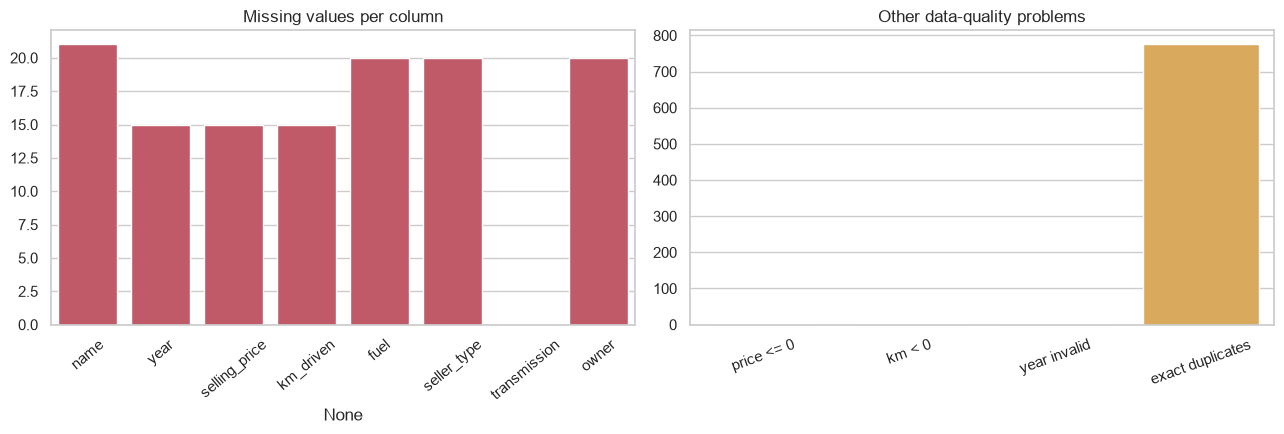

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# left graph: missing values
missing = raw.isna().sum()
sns.barplot(x=missing.index, y=missing.values, ax=ax[0], color="#d1495b")
ax[0].set_title("Missing values per column")
ax[0].tick_params(axis="x", rotation=40)

# right graph: other problems
problems = {"price <= 0": (raw.selling_price <= 0).sum(),
            "km < 0": (raw.km_driven < 0).sum(),
            "year invalid": ((raw.year > CUR_YEAR) | (raw.year < 1980)).sum(),
            "exact duplicates": raw.duplicated().sum()}
sns.barplot(x=list(problems.keys()), y=list(problems.values()), ax=ax[1], color="#edae49")
ax[1].set_title("Other data-quality problems")
ax[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig("charts/01_data_quality.png", dpi=130)
plt.show()

## 4. Data cleaning
Order matters: fix the text **first**, so `DIESEL` and `Diesel` become the same value, and only then remove duplicates.

In [8]:
df = raw.copy()
log = {"raw_rows": len(raw)}          # small diary of what we changed

# 4a. Standardise text: remove extra spaces and use the same capital letters
for c in ["name", "fuel", "seller_type", "transmission", "owner"]:
    df[c] = df[c].astype("string").str.strip().str.replace(r"\s+", " ", regex=True).str.title()

# 4b. Remove duplicate rows
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
log["duplicates_removed"] = before - len(df)

# 4c. Wrong values -> make them empty (NaN) so we can fill them later
df.loc[(df.year > CUR_YEAR) | (df.year < 1980), "year"] = np.nan
df.loc[df.km_driven < 0, "km_driven"] = np.nan
df.loc[df.selling_price <= 0, "selling_price"] = np.nan

# 4d. Drop rows we cannot repair (no price or no car name)
before = len(df)
df = df.dropna(subset=["selling_price", "name"]).reset_index(drop=True)
log["dropped_missing_price_or_name"] = before - len(df)

# 4e. Fill the remaining gaps: median for numbers, most common value for text
log["imputed"] = df.isna().sum()[lambda s: s > 0].to_dict()
df["year"] = df["year"].fillna(df["year"].median())
df["km_driven"] = df["km_driven"].fillna(df["km_driven"].median())
for c in ["fuel", "seller_type", "owner"]:
    df[c] = df[c].fillna(df[c].mode()[0])

# 4f. Outliers: limit very high mileage to the 99.5th percentile
#     (high prices are kept because luxury cars are real)
cap = df.km_driven.quantile(0.995)
log["km_cap"] = float(cap)
log["km_rows_capped"] = int((df.km_driven > cap).sum())
df["km_driven"] = df["km_driven"].clip(upper=cap)

# 4g. Correct data types
df["year"] = df["year"].astype(int)
for c in ["fuel", "seller_type", "transmission", "owner"]:
    df[c] = df[c].astype("category")
df["name"] = df["name"].astype(str)

log["clean_rows"] = len(df)
log

{'raw_rows': 4390,
 'duplicates_removed': 787,
 'dropped_missing_price_or_name': 36,
 'imputed': {'year': 15,
  'km_driven': 16,
  'fuel': 20,
  'seller_type': 20,
  'owner': 19},
 'km_cap': 250000.0,
 'km_rows_capped': 17,
 'clean_rows': 3567}

In [9]:
# Check: nothing left to fix
print("Missing values left:", df.isna().sum().sum())
print("Duplicates left    :", df.duplicated().sum())
print(df.dtypes)
df.describe().T

Missing values left: 0
Duplicates left    : 8
name                  str
year                int64
selling_price     float64
km_driven         float64
fuel             category
seller_type      category
transmission     category
owner            category
dtype: object


,count,mean,std,min,25%,50%,75%,max
year,3567.0,2012.970563,4.242373,1992.0,2010.0,2013.0,2016.0,2020.0
selling_price,3567.0,475903.886740,511833.248724,20000.0,200000.0,350000.0,600000.0,8900000.0
km_driven,3567.0,68647.050743,43989.947397,1.0,36500.0,60000.0,90000.0,250000.0


## 5. Feature engineering
New columns made from the old ones help the model learn better.

In [10]:
df["car_age"] = CUR_YEAR - df["year"]                          # older car = cheaper
df["age_sq"] = df["car_age"] ** 2                              # price drops fast at first, then slowly
df["log_km"] = np.log1p(df["km_driven"])                       # makes km less skewed
df["km_per_year"] = df["km_driven"] / df["car_age"].clip(lower=1)   # how heavily the car was used

# brand = first word of the name
df["brand"] = df["name"].str.split().str[0]
df.loc[df.brand == "Land", "brand"] = "Land Rover"

# put very rare brands (less than 5 cars) into one group called "Other"
brand_count = df["brand"].value_counts()
df["brand"] = df["brand"].where(df["brand"].isin(brand_count[brand_count >= 5].index), "Other")

df.to_csv("preowned_cars_clean.csv", index=False)
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,car_age,age_sq,log_km,km_per_year,brand
0,Maruti 800 Ac,2013,60000.0,70000.0,Petrol,Individual,Manual,First Owner,13,169,11.156265,5384.615385,Maruti
1,Hyundai Verna 1.6 Sx,2012,600000.0,60000.0,Diesel,Individual,Manual,First Owner,14,196,11.002117,4285.714286,Hyundai
2,Datsun Redigo T Option,2017,250000.0,46000.0,Petrol,Individual,Manual,First Owner,9,81,10.736418,5111.111111,Datsun
3,Honda Amaze Vx I-Dtec,2014,450000.0,141000.0,Diesel,Individual,Manual,Second Owner,12,144,11.856522,11750.000000,Honda
4,Maruti Alto Lx Bsiii,2007,140000.0,125000.0,Petrol,Individual,Manual,First Owner,19,361,11.736077,6578.947368,Maruti


## 6. Exploratory graphs

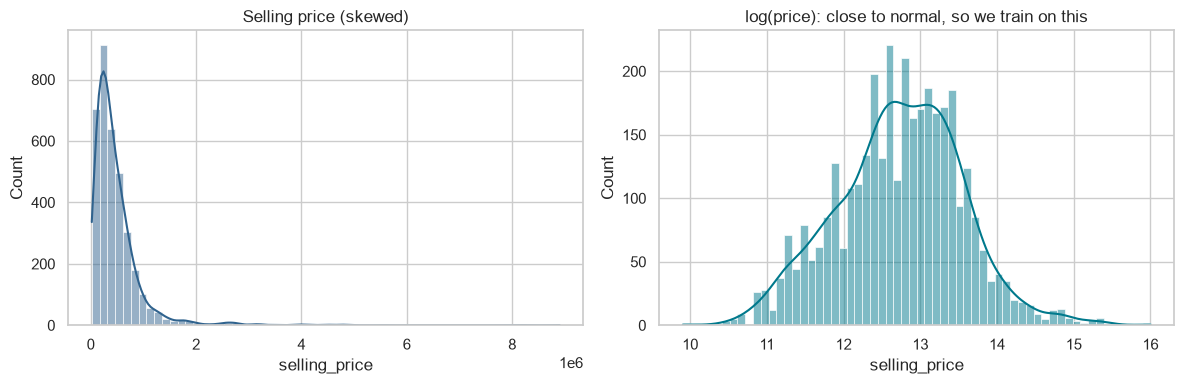

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df.selling_price, bins=60, kde=True, ax=ax[0], color="#30638e")
ax[0].set_title("Selling price (skewed)")
sns.histplot(np.log1p(df.selling_price), bins=60, kde=True, ax=ax[1], color="#00798c")
ax[1].set_title("log(price): close to normal, so we train on this")
plt.tight_layout()
plt.savefig("charts/02_price_distribution.png", dpi=130)
plt.show()

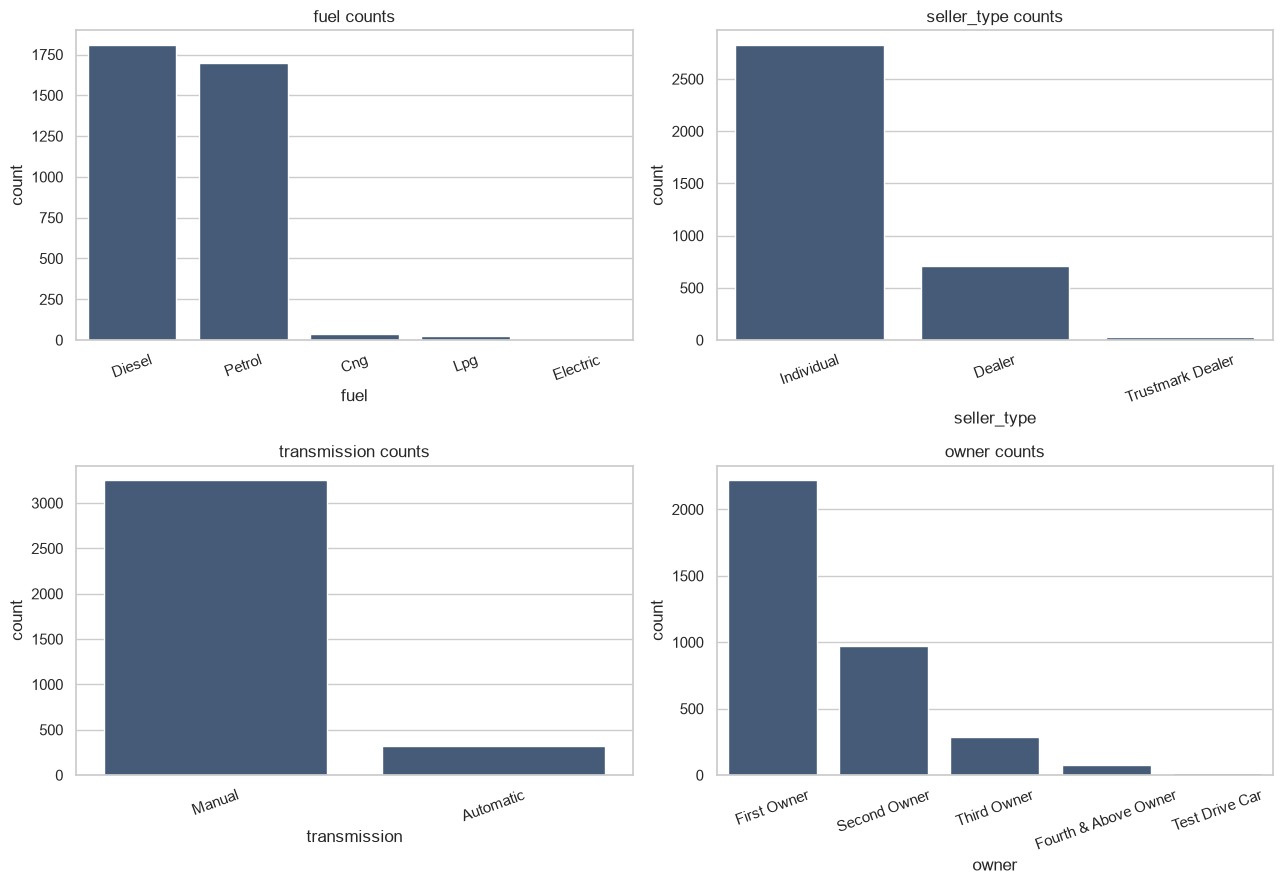

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for a, c in zip(ax.ravel(), ["fuel", "seller_type", "transmission", "owner"]):
    sns.countplot(data=df, x=c, order=df[c].value_counts().index, ax=a, color="#3d5a80")
    a.set_title(f"{c} counts")
    a.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig("charts/03_categorical_counts.png", dpi=130)
plt.show()

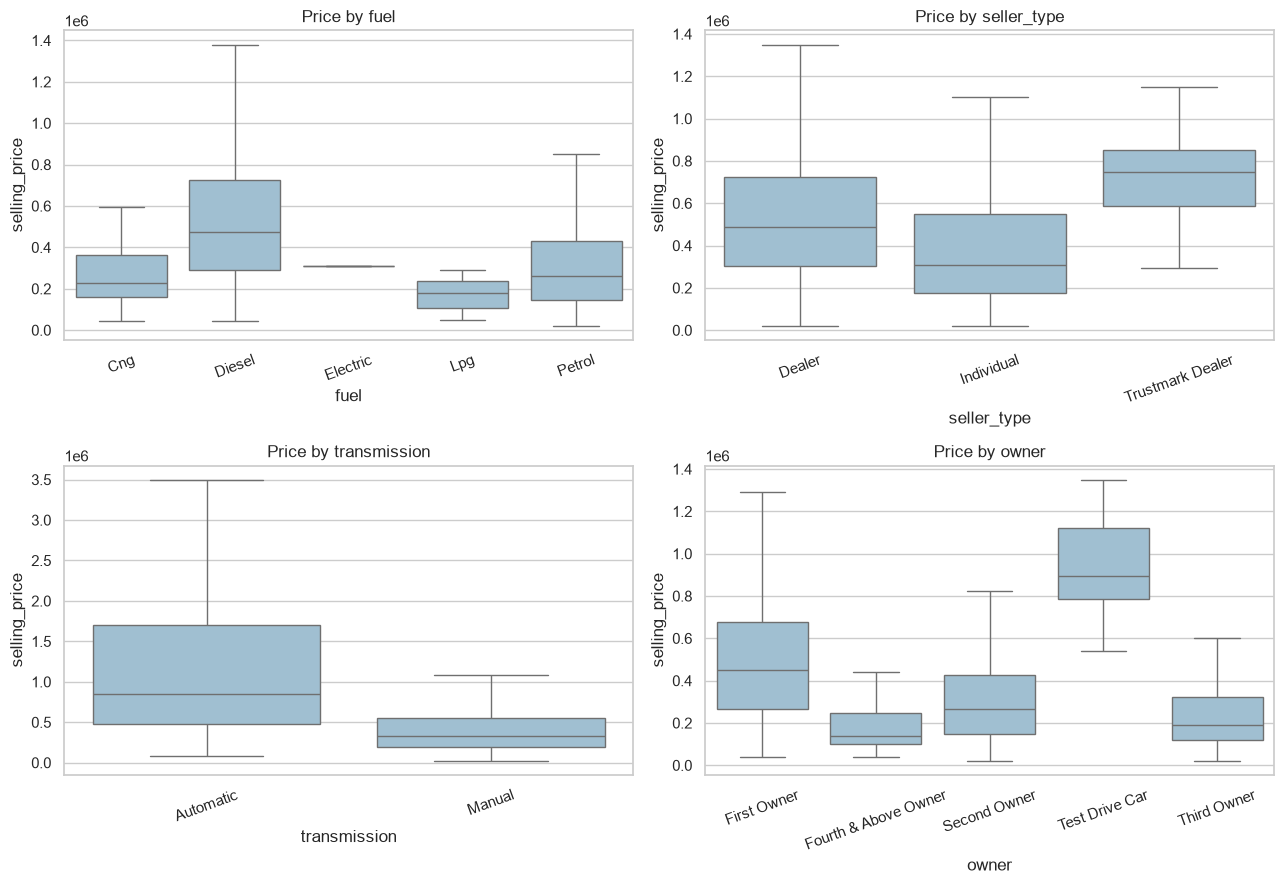

In [13]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for a, c in zip(ax.ravel(), ["fuel", "seller_type", "transmission", "owner"]):
    sns.boxplot(data=df, x=c, y="selling_price", ax=a, showfliers=False, color="#98c1d9")
    a.set_title(f"Price by {c}")
    a.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig("charts/04_price_by_category.png", dpi=130)
plt.show()

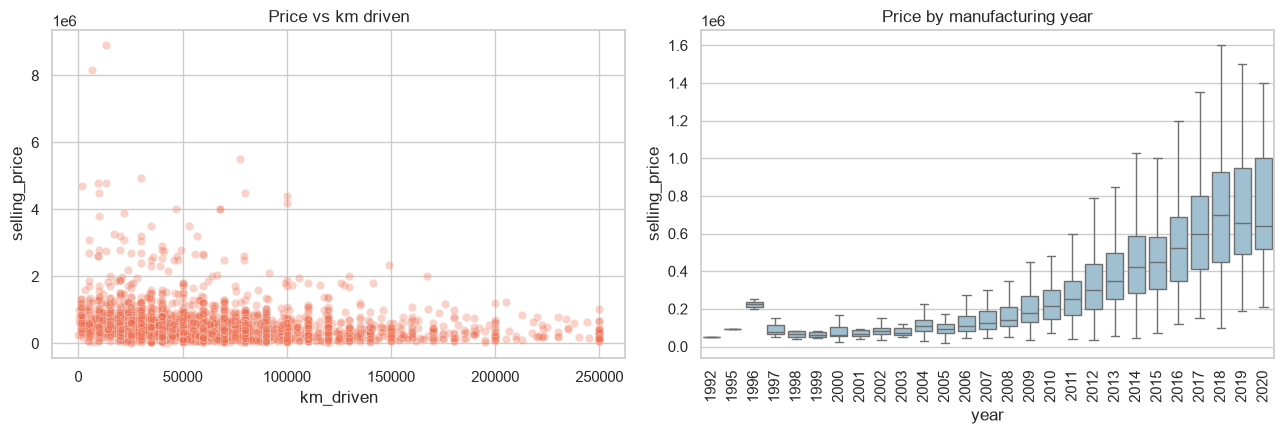

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=df, x="km_driven", y="selling_price", alpha=0.3, ax=ax[0], color="#ee6c4d")
ax[0].set_title("Price vs km driven")
sns.boxplot(data=df, x="year", y="selling_price", showfliers=False, ax=ax[1], color="#98c1d9")
ax[1].set_title("Price by manufacturing year")
ax[1].tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.savefig("charts/05_price_vs_year_km.png", dpi=130)
plt.show()

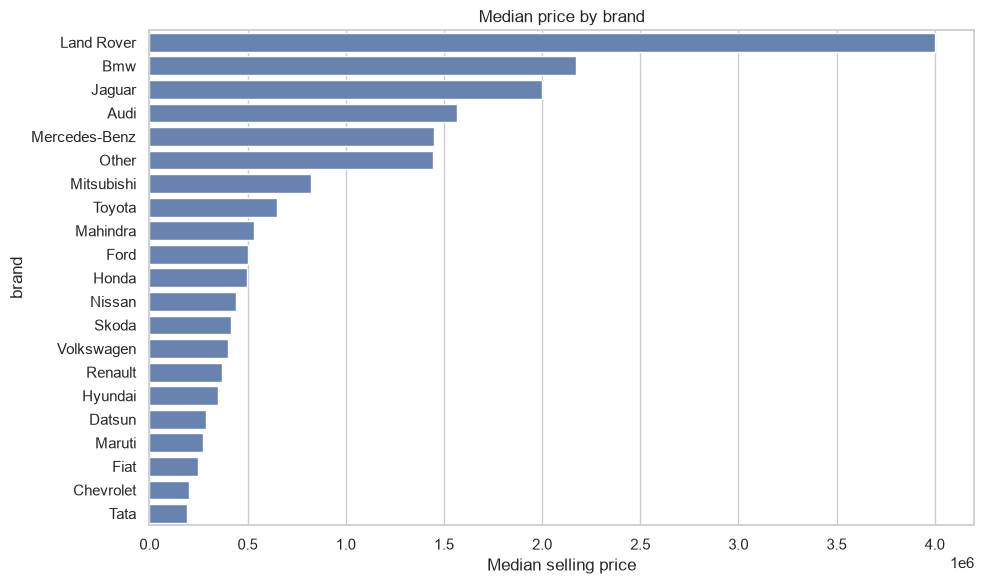

In [15]:
brand_price = df.groupby("brand").selling_price.median().sort_values(ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(x=brand_price.values, y=brand_price.index, color="#5c80bc")
plt.title("Median price by brand")
plt.xlabel("Median selling price")
plt.tight_layout()
plt.savefig("charts/06_price_by_brand.png", dpi=130)
plt.show()

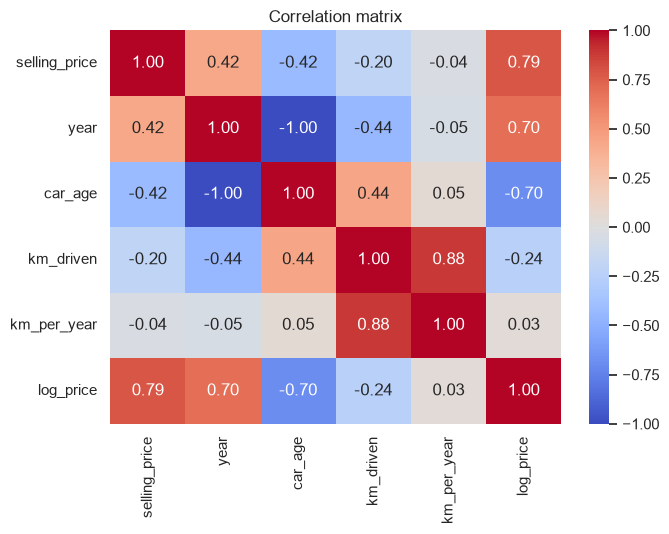

In [16]:
corr_data = df[["selling_price", "year", "car_age", "km_driven", "km_per_year"]].copy()
corr_data["log_price"] = np.log1p(corr_data.selling_price)

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_data.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.tight_layout()
plt.savefig("charts/07_correlation.png", dpi=130)
plt.show()

## 7. Train and compare models
- **Target = log(price)** because prices are very skewed. We convert predictions back to rupees for the final metrics.
- The words in the car name (model, engine, trim like "VXI", "Diesel") are turned into numbers with **TF-IDF**. This is the biggest reason for the high accuracy.
- Data split: **80% train / 20% test**, plus 5-fold cross-validation.

In [17]:
# Input columns (X) and the value we want to predict (y)
text_col = "name"
cat_cols = ["brand", "fuel", "seller_type", "transmission", "owner"]
num_cols = ["car_age", "age_sq", "log_km", "km_per_year"]

X = df[[text_col] + cat_cols + num_cols].copy()
for c in cat_cols:
    X[c] = X[c].astype(str)
y = np.log1p(df["selling_price"])

# 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Preprocessing: convert every column type into numbers
pre = ColumnTransformer([
    ("name_words", TfidfVectorizer(token_pattern=r"[^ ]+", sublinear_tf=True), text_col),
    ("categories", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("numbers", StandardScaler(), num_cols)])

# Function to calculate all metrics in rupees
def get_metrics(y_true_log, y_pred_log):
    y_true = np.expm1(y_true_log)       # log price -> real price
    y_pred = np.expm1(y_pred_log)
    return {"R2_log": r2_score(y_true_log, y_pred_log),
            "R2": r2_score(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "MAPE": float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100)}

models = {
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=0.3)": Ridge(alpha=0.3),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

kfold = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for model_name, model in models.items():
    pipe = Pipeline([("pre", pre), ("model", model)])
    cv_score = cross_val_score(pipe, X_train, y_train, cv=kfold, scoring="r2").mean()
    pipe.fit(X_train, y_train)
    row = get_metrics(y_test, pipe.predict(X_test))
    row["Model"] = model_name
    row["CV_R2_log"] = cv_score
    rows.append(row)

results = pd.DataFrame(rows).set_index("Model")
results.round(3)

,R2_log,R2,MAE,RMSE,MAPE,CV_R2_log
Model,,,,,,
Linear Regression,0.851,0.802,84242.543,190350.256,21.667,0.844
Ridge (alpha=0.3),0.881,0.879,78799.738,148938.870,20.856,0.888
Random Forest,0.824,0.751,99735.069,213355.426,24.279,0.842
Gradient Boosting,0.806,0.690,112674.596,238395.469,27.286,0.831


In [18]:
# Tune Ridge: try each alpha value and keep the best one
search = GridSearchCV(
    Pipeline([("pre", pre), ("model", Ridge())]),
    param_grid={"model__alpha": [0.05, 0.1, 0.2, 0.3, 0.5, 0.8, 1, 2]},
    cv=kfold, scoring="r2", n_jobs=-1)
search.fit(X_train, y_train)
print("Best params:", search.best_params_, "| CV R2 (log):", round(search.best_score_, 4))

row = get_metrics(y_test, search.best_estimator_.predict(X_test))
row["Model"] = "Ridge (tuned)"
row["CV_R2_log"] = search.best_score_
results = pd.concat([results, pd.DataFrame([row]).set_index("Model")])
results.round(3)

Best params: {'model__alpha': 0.8} | CV R2 (log): 0.8898


,R2_log,R2,MAE,RMSE,MAPE,CV_R2_log
Model,,,,,,
Linear Regression,0.851,0.802,84242.543,190350.256,21.667,0.844
Ridge (alpha=0.3),0.881,0.879,78799.738,148938.870,20.856,0.888
Random Forest,0.824,0.751,99735.069,213355.426,24.279,0.842
Gradient Boosting,0.806,0.690,112674.596,238395.469,27.286,0.831
Ridge (tuned),0.881,0.863,79723.212,158095.889,20.990,0.890


## 8. Metrics and evaluation graphs

In [19]:
# Pick the model with the best R2 on the test data
final_name = results["R2"].idxmax()
if final_name == "Ridge (tuned)":
    final = search.best_estimator_
else:
    final = Pipeline([("pre", pre), ("model", models[final_name])]).fit(X_train, y_train)
print("Final model:", final_name)

pred_log = final.predict(X_test)
final_metrics = get_metrics(y_test, pred_log)
print(f"R2 (price scale): {final_metrics['R2']:.3f}")
print(f"MAE : Rs {final_metrics['MAE']:,.0f}")
print(f"RMSE: Rs {final_metrics['RMSE']:,.0f}")
print(f"MAPE: {final_metrics['MAPE']:.1f}%")
results.round(3).to_csv("model_metrics.csv")

Final model: Ridge (alpha=0.3)
R2 (price scale): 0.879
MAE : Rs 78,800
RMSE: Rs 148,939
MAPE: 20.9%


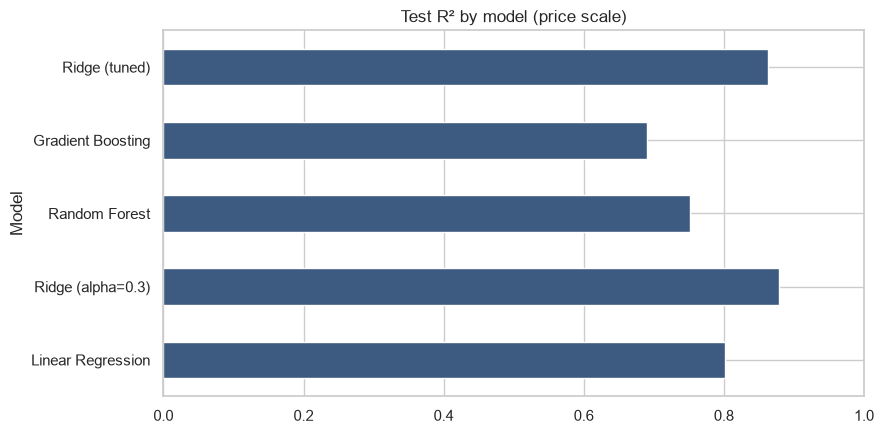

In [20]:
plt.figure(figsize=(9, 4.5))
results["R2"].plot(kind="barh", color="#3d5a80")
plt.title("Test R² by model (price scale)")
plt.xlim(0, 1)
plt.tight_layout()
plt.savefig("charts/08_model_comparison.png", dpi=130)
plt.show()

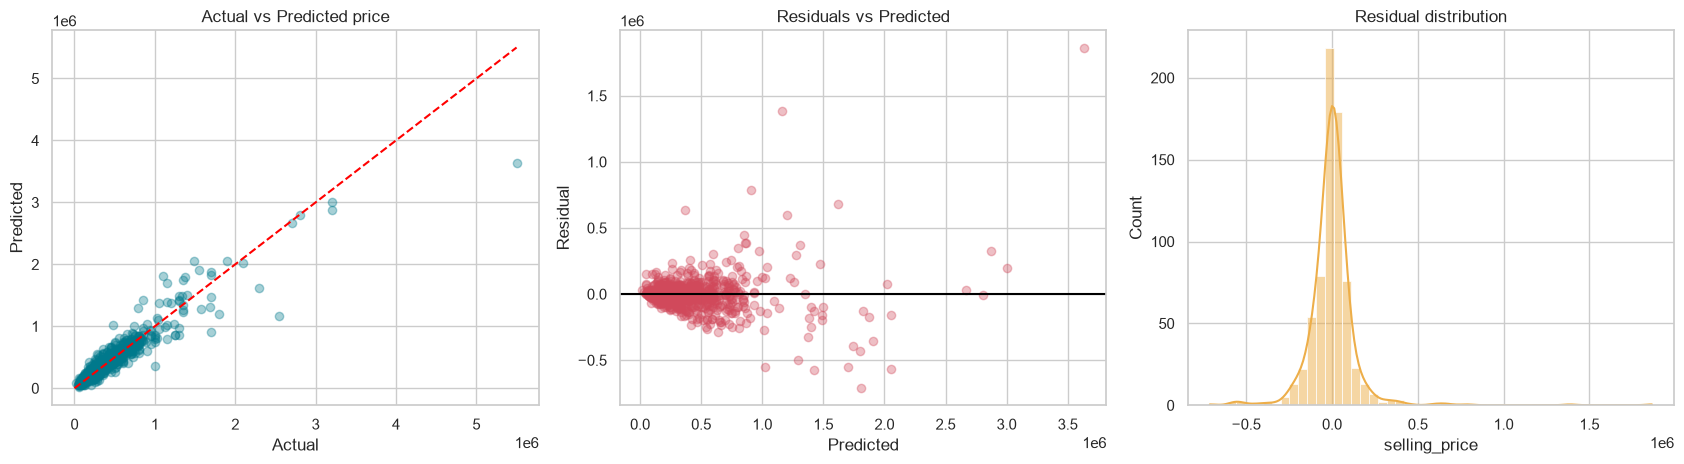

In [21]:
actual = np.expm1(y_test)          # real prices
predicted = np.expm1(pred_log)     # predicted prices
residual = actual - predicted      # error of each prediction

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))

# 1) Actual vs predicted (points near the red line = good)
ax[0].scatter(actual, predicted, alpha=0.35, color="#00798c")
line = [0, max(actual.max(), predicted.max())]
ax[0].plot(line, line, "r--")
ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted")
ax[0].set_title("Actual vs Predicted price")

# 2) Residuals vs predicted
ax[1].scatter(predicted, residual, alpha=0.35, color="#d1495b")
ax[1].axhline(0, color="k")
ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Residual")
ax[1].set_title("Residuals vs Predicted")

# 3) Residual distribution
sns.histplot(residual, bins=50, kde=True, ax=ax[2], color="#edae49")
ax[2].set_title("Residual distribution")

plt.tight_layout()
plt.savefig("charts/09_actual_vs_predicted.png", dpi=130)
plt.show()

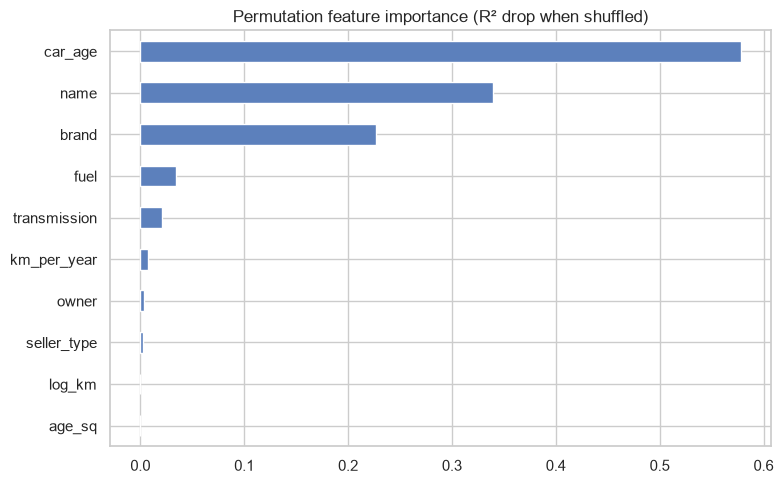

In [22]:
# Which input column matters most? Shuffle one column and see how much R2 drops.
pi = permutation_importance(final, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1)
importance = pd.Series(pi.importances_mean, index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
importance.plot(kind="barh", color="#5c80bc")
plt.title("Permutation feature importance (R² drop when shuffled)")
plt.tight_layout()
plt.savefig("charts/10_feature_importance.png", dpi=130)
plt.show()

## 9. Save the model and predict a new car

In [24]:
joblib.dump(final, "car_price_model.joblib")

known_brands = set(X["brand"])

def predict_price(name, year, km_driven, fuel, seller_type, transmission, owner):
    # same steps we used on the training data
    name = name.strip().title()
    brand = name.split()[0]
    if brand == "Land":
        brand = "Land Rover"
    if brand not in known_brands:
        brand = "Other"
    age = CUR_YEAR - year

    car = pd.DataFrame([{
        "name": name, "brand": brand, "fuel": fuel.title(),
        "seller_type": seller_type.title(), "transmission": transmission.title(),
        "owner": owner.title(), "car_age": age, "age_sq": age ** 2,
        "log_km": np.log1p(km_driven), "km_per_year": km_driven / max(age, 1)}])

    return float(np.expm1(final.predict(car))[0])

price = predict_price("Maruti Swift Dzire VDI", 2015, 70000, "Diesel", "Individual", "Manual", "First Owner")
print(f"Estimated price: Rs {price:,.0f}")

Estimated price: Rs 481,824
